# Notebook 03 — Đánh giá ba visual baseline ResNet-50

Notebook này hướng dẫn đánh giá ba model `person_only`, `context_only` và `person_context` trên EMOTIC. Hãy chạy các cell theo thứ tự từ trên xuống trên Colab có GPU.

## Dữ liệu đầu vào

Mỗi model cần một thư mục export chứa `model.pt`, `config.json`, `label_map.json` và `metrics.json`. Notebook tự tìm phiên bản mới nhất trong `models/` hoặc `checkpoints/` trên Drive và kiểm tra cấu hình cùng thứ tự 26 nhãn trước khi inference.

## Thứ tự xử lý

1. Mount Drive, đồng bộ source code và giải nén ảnh vào `/content`.
2. Nạp ba model, tạo validation/test dataset và chạy inference.
3. Chọn threshold từng nhãn và `k` của constant top-k chỉ trên validation.
4. Tính metric trên test, so sánh `union`/`majority`, bỏ `Engagement` và phân nhóm theo số người.
5. Chạy paired bootstrap, region ablation và target swap.
6. Lưu predictions, metrics, bảng CSV và hình so sánh vào `outputs/resnet_evaluation/<run_id>/`.

Các model được train bằng nhãn `union`; kết quả `majority` chỉ dùng để kiểm tra độ nhạy với cách gộp nhãn. Notebook này không đánh giá explanation faithfulness hoặc VLM yes-probability.


## 1. Mount Drive, đồng bộ source code và cài dependency

Notebook chỉ chạy trên Colab. Source code được clone vào `/content` để đọc ảnh và import nhanh hơn.


In [7]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import subprocess
import sys

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition"
)
REPO_URL = (
    "https://github.com/minh-1105/"
    "-Explainable-Contextual-Emotion-Recognition-via-"
    "Text-Guided-Chain-of-Thought-Reasoning.git"
)
CODE_ROOT = Path("/content/contextual-emotion-reasoning")

assert DRIVE_ROOT.is_dir(), f"Không tìm thấy project trên Drive: {DRIVE_ROOT}"
if not CODE_ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(CODE_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(CODE_ROOT), "pull", "--ff-only"], check=True)

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements.txt")],
    check=True,
)
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

print("Drive root:", DRIVE_ROOT)
print("Code root :", CODE_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive root: /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition
Code root : /content/contextual-emotion-reasoning


## 2. Protocol cố định trước khi dùng test

- Threshold từng label và `k` của constant top-k được chọn trên validation.
- Test không được dùng để tune bất kỳ giá trị nào.
- Paired bootstrap resample theo **ảnh**, giữ các người trong cùng ảnh đi cùng nhau.
- `ΔRandom` bỏ person crop giống `ΔPerson`, nhưng che một vùng context ngẫu nhiên có cùng kích thước bbox; nhờ vậy nó kiểm soát vị trí vùng che.
- Swap accuracy là tỉ lệ dự đoán sau swap có sample-F1 với nhãn target mới lớn hơn sample-F1 với nhãn target cũ; trường hợp hòa không tính đúng.


In [8]:
from datetime import datetime
import json
import os
import platform
import random
import shutil
import time
import zipfile

import numpy as np
import torch

EMOTIC_ROOT = DRIVE_ROOT / "data/raw/raw/emotic"
PAMI_ROOT = EMOTIC_ROOT / "PAMI"
CVPR_ROOT = EMOTIC_ROOT / "CVPR"
ANNOTATION_PATH = PAMI_ROOT / "Annotations/Annotations/Annotations.mat"

LOCAL_EMOTIC_ROOT = Path("/content/emotic")
IMAGE_ARCHIVES = (
    (PAMI_ROOT / "pami_emotic.zip", LOCAL_EMOTIC_ROOT / "PAMI", "emotic", 23185),
    (CVPR_ROOT / "cvpr_emotic.zip", LOCAL_EMOTIC_ROOT / "CVPR", "cvpr_emotic", 18302),
)

OUTPUT_ROOT = DRIVE_ROOT / "outputs"
MODEL_ROOT = DRIVE_ROOT / "models"
CHECKPOINT_EXPORT_ROOT = DRIVE_ROOT / "checkpoints"

EVAL_CONFIG = {
    "batch_size": 32,
    "num_workers": min(8, os.cpu_count() or 1),
    "threshold_grid": [round(value, 2) for value in np.arange(0.05, 1.0, 0.05)],
    "bootstrap_resamples": 2000,
    "seed": 42,
    "label_policies": ["union", "majority"],
    "region_ablation": True,
    "target_swap": True,
    "target_swap_max_pairs": None,
}


def extract_images(archive_path, extract_dir, root_name, expected_files):
    # Giải nén zip ảnh từ Drive vào ổ local của Colab, mỗi runtime một lần.
    image_root = extract_dir / root_name
    marker = extract_dir / ".extracted"
    if marker.is_file():
        return image_root
    assert archive_path.is_file(), f"Thiếu file zip: {archive_path}"
    shutil.rmtree(extract_dir, ignore_errors=True)
    extract_dir.mkdir(parents=True)
    started = time.time()
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(extract_dir)
    file_count = sum(1 for path in image_root.rglob("*") if path.is_file())
    assert file_count == expected_files, (
        f"{archive_path.name}: {file_count} file, cần {expected_files}"
    )
    marker.touch()
    print(f"Giải nén {archive_path.name}: {file_count:,} file, {time.time() - started:.0f}s")
    return image_root


assert ANNOTATION_PATH.is_file(), f"Thiếu annotation: {ANNOTATION_PATH}"
IMAGE_ROOTS = tuple(extract_images(*spec) for spec in IMAGE_ARCHIVES)

RUN_ID = datetime.now().strftime("%Y%m%d-%H%M%S")
RUN_DIR = OUTPUT_ROOT / "resnet_evaluation" / RUN_ID
PREDICTION_DIR = RUN_DIR / "predictions"
METRIC_DIR = RUN_DIR / "metrics"
FIGURE_DIR = RUN_DIR / "figures"
for path in (PREDICTION_DIR, METRIC_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=False)

(RUN_DIR / "config.json").write_text(
    json.dumps(EVAL_CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
)

random.seed(EVAL_CONFIG["seed"])
np.random.seed(EVAL_CONFIG["seed"])
torch.manual_seed(EVAL_CONFIG["seed"])
torch.cuda.manual_seed_all(EVAL_CONFIG["seed"])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Hãy bật GPU: Runtime > Change runtime type > GPU"
commit = subprocess.run(
    ["git", "-C", str(CODE_ROOT), "rev-parse", "HEAD"],
    check=True, capture_output=True, text=True,
).stdout.strip()
(RUN_DIR / "environment.txt").write_text(
    "\n".join([
        f"python={platform.python_version()}",
        f"torch={torch.__version__}",
        f"cuda={torch.version.cuda}",
        f"gpu={torch.cuda.get_device_name(0)}",
        f"git_commit={commit}",
    ]) + "\n",
    encoding="utf-8",
)
print("Run dir:", RUN_DIR)
print("Device :", device)
print("Commit :", commit)


Run dir: /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/outputs/resnet_evaluation/20261101-034030
Device : cuda
Commit : 0e4b81fc6c9ee9c57abd270ebcb64e743e83fde0


## 3. Tìm và xác minh ba model export

Notebook hỗ trợ cả layout chuẩn `models/emotic_<mode>_resnet50/<run_id>/` và layout thực tế hiện có `checkpoints/emotic_<mode>_resnet50/<run_id>/`. Mỗi export phải có đủ trọng số, config và label map đúng thứ tự 26 nhãn.


In [9]:
from src.datasets.emotic_dataset import EMOTION_LABELS

EXPERIMENTS = ("person_only", "context_only", "person_context")


def find_latest_export(experiment_name):
    model_name = f"emotic_{experiment_name}_resnet50"
    candidates = []
    for root in (MODEL_ROOT, CHECKPOINT_EXPORT_ROOT):
        model_dir = root / model_name
        if model_dir.is_dir():
            candidates.extend(
                path for path in model_dir.iterdir()
                if path.is_dir() and (path / "model.pt").is_file()
            )
    assert candidates, (
        f"Không tìm thấy {model_name} trong {MODEL_ROOT} hoặc {CHECKPOINT_EXPORT_ROOT}"
    )
    return sorted(candidates, key=lambda path: path.name)[-1]


MODEL_EXPORTS = {name: find_latest_export(name) for name in EXPERIMENTS}
MODEL_CONFIGS = {}
for name, export_dir in MODEL_EXPORTS.items():
    config = json.loads((export_dir / "config.json").read_text(encoding="utf-8"))
    label_map = json.loads((export_dir / "label_map.json").read_text(encoding="utf-8"))
    expected_map = {label: index for index, label in enumerate(EMOTION_LABELS)}
    assert label_map == expected_map, f"Sai thứ tự label: {export_dir}"
    assert config["experiment_name"] == name
    assert config["backbone"] == "resnet50"
    assert config["category_policy"] == "union", (
        "Protocol hiện tại giả định ba model được train bằng union"
    )
    MODEL_CONFIGS[name] = config
    print(f"{name:15} -> {export_dir}")

for key in ("image_size", "crop_padding", "strict_images"):
    values = {MODEL_CONFIGS[name][key] for name in EXPERIMENTS}
    assert len(values) == 1, f"Ba export không đồng nhất {key}: {values}"

selected_exports = {name: str(path) for name, path in MODEL_EXPORTS.items()}
(RUN_DIR / "selected_models.json").write_text(
    json.dumps(selected_exports, ensure_ascii=False, indent=2), encoding="utf-8"
)


person_only     -> /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/checkpoints/emotic_person_only_resnet50/20261019-091248
context_only    -> /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/checkpoints/emotic_context_only_resnet50/20261019-093151
person_context  -> /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/checkpoints/emotic_person_context_resnet50/20261019-094057


448

## 4. Dataset validation/test cho `union` và `majority`

Inference ảnh chỉ chạy một lần cho mỗi model. Hai policy có cùng sample order; chỉ vector ground truth thay đổi. Threshold được chọn riêng trên validation cho từng policy.


In [10]:
from collections import Counter

from torch.utils.data import DataLoader
from torchvision import transforms
from src.datasets.emotic_dataset import EmoticDataset

reference_config = MODEL_CONFIGS["person_context"]
image_size = reference_config["image_size"]
eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])


def make_dataset(split, policy):
    return EmoticDataset(
        annotation_path=ANNOTATION_PATH,
        image_roots=IMAGE_ROOTS,
        split=split,
        context_transform=eval_transform,
        person_transform=eval_transform,
        category_policy=policy,
        crop_padding=reference_config["crop_padding"],
        strict_images=reference_config["strict_images"],
    )


datasets = {
    policy: {split: make_dataset(split, policy) for split in ("val", "test")}
    for policy in EVAL_CONFIG["label_policies"]
}
for split in ("val", "test"):
    union_ids = [sample.sample_id for sample in datasets["union"][split].samples]
    majority_ids = [sample.sample_id for sample in datasets["majority"][split].samples]
    assert union_ids == majority_ids, f"Sample order lệch ở {split}"


def targets_without_image_io(dataset):
    return np.stack([
        dataset._category_target(sample).numpy() for sample in dataset.samples
    ]).astype(np.int32)


targets = {
    policy: {
        split: targets_without_image_io(datasets[policy][split])
        for split in ("val", "test")
    }
    for policy in EVAL_CONFIG["label_policies"]
}

loader_kwargs = {
    "batch_size": EVAL_CONFIG["batch_size"],
    "shuffle": False,
    "num_workers": EVAL_CONFIG["num_workers"],
    "pin_memory": True,
    "persistent_workers": EVAL_CONFIG["num_workers"] > 0,
}
loaders = {
    split: DataLoader(datasets["union"][split], **loader_kwargs)
    for split in ("val", "test")
}

metadata = {}
for split in ("val", "test"):
    dataset = datasets["union"][split]
    image_ids = [sample.relative_image_path for sample in dataset.samples]
    counts = Counter(image_ids)
    metadata[split] = {
        "sample_ids": [sample.sample_id for sample in dataset.samples],
        "image_ids": image_ids,
        "people_per_image": np.asarray([counts[value] for value in image_ids]),
    }
    print(
        f"{split}: {len(dataset):,} người / {len(counts):,} ảnh; "
        f"union positives={targets['union'][split].sum():,}; "
        f"majority positives={targets['majority'][split].sum():,}"
    )


val: 3,334 người / 2,088 ảnh; union positives=20,527; majority positives=4,946
test: 7,280 người / 4,389 ảnh; union positives=32,145; majority positives=9,989


## 5. Khôi phục kiến trúc và chạy inference

`model.pt` là state dict hoàn chỉnh dùng cho inference. Notebook dựng lại đúng kiến trúc Notebook 02, không tải pretrained weights, rồi nạp state dict.


In [11]:
import torch.nn as nn
from torchvision.models import resnet50
from tqdm.auto import tqdm


def make_encoder(freeze=False):
    backbone = resnet50(weights=None)
    feature_dim = backbone.fc.in_features
    backbone.fc = nn.Identity()
    if freeze:
        for parameter in backbone.parameters():
            parameter.requires_grad = False
    return backbone, feature_dim


class VisualBaseline(nn.Module):
    def __init__(self, mode, num_classes=26, freeze_backbone=False, dropout=0.3):
        super().__init__()
        if mode not in EXPERIMENTS:
            raise ValueError(f"Unsupported mode: {mode}")
        self.mode = mode
        if mode in {"person_only", "person_context"}:
            self.person_encoder, person_dim = make_encoder(freeze_backbone)
        if mode in {"context_only", "person_context"}:
            self.context_encoder, context_dim = make_encoder(freeze_backbone)
        input_dim = (
            person_dim if mode == "person_only" else
            context_dim if mode == "context_only" else
            person_dim + context_dim
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(input_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, person_image, context_image):
        if self.mode == "person_only":
            features = self.person_encoder(person_image)
        elif self.mode == "context_only":
            features = self.context_encoder(context_image)
        else:
            features = torch.cat(
                (self.person_encoder(person_image), self.context_encoder(context_image)),
                dim=1,
            )
        return self.classifier(features)


models = {}
for name in EXPERIMENTS:
    config = MODEL_CONFIGS[name]
    model = VisualBaseline(
        mode=name,
        num_classes=len(EMOTION_LABELS),
        freeze_backbone=config["freeze_backbone"],
        dropout=config["dropout"],
    )
    state_dict = torch.load(
        MODEL_EXPORTS[name] / "model.pt", map_location="cpu", weights_only=True
    )
    model.load_state_dict(state_dict, strict=True)
    models[name] = model.to(device).eval()


@torch.inference_mode()
def infer(model, loader, description):
    probabilities = []
    for batch in tqdm(loader, desc=description):
        logits = model(
            batch["person_image"].to(device, non_blocking=True),
            batch["context_image"].to(device, non_blocking=True),
        )
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probabilities)


probabilities = {name: {} for name in EXPERIMENTS}
for name, model in models.items():
    for split in ("val", "test"):
        values = infer(model, loaders[split], f"{name} {split}")
        assert values.shape == targets["union"][split].shape
        probabilities[name][split] = values
        np.savez_compressed(
            PREDICTION_DIR / f"{name}_{split}.npz",
            sample_ids=np.asarray(metadata[split]["sample_ids"]),
            image_ids=np.asarray(metadata[split]["image_ids"]),
            targets_union=targets["union"][split],
            targets_majority=targets["majority"][split],
            probabilities=values,
        )


person_only val:   0%|          | 0/105 [00:00<?, ?it/s]

person_only test:   0%|          | 0/228 [00:00<?, ?it/s]

context_only val:   0%|          | 0/105 [00:00<?, ?it/s]

context_only test:   0%|          | 0/228 [00:00<?, ?it/s]

person_context val:   0%|          | 0/105 [00:00<?, ?it/s]

person_context test:   0%|          | 0/228 [00:00<?, ?it/s]

## 6. A — Standard evaluation

Cell này khóa threshold và constant top-k trên validation, sau đó áp dụng nguyên trạng lên test. Kết quả per-class bao gồm AP, precision, recall, F1 và TP/FP/FN/TN để phục vụ multi-label error analysis.


In [12]:
import csv
from src.evaluation import (
    constant_top_k_predictions,
    multilabel_metrics,
    select_constant_top_k,
    select_per_class_thresholds,
)


def json_safe(value):
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.floating, float)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.integer, int)):
        return int(value)
    return value


thresholds = {policy: {} for policy in EVAL_CONFIG["label_policies"]}
standard_results = {policy: {} for policy in EVAL_CONFIG["label_policies"]}
test_predictions = {policy: {} for policy in EVAL_CONFIG["label_policies"]}

for policy in EVAL_CONFIG["label_policies"]:
    for name in EXPERIMENTS:
        selected = select_per_class_thresholds(
            targets[policy]["val"],
            probabilities[name]["val"],
            EVAL_CONFIG["threshold_grid"],
        )
        thresholds[policy][name] = selected
        predictions = (probabilities[name]["test"] >= selected).astype(np.int32)
        test_predictions[policy][name] = predictions
        standard_results[policy][name] = multilabel_metrics(
            targets[policy]["test"],
            probabilities[name]["test"],
            predictions=predictions,
            class_names=EMOTION_LABELS,
        )

        with (METRIC_DIR / f"per_class_{policy}_{name}.csv").open(
            "w", newline="", encoding="utf-8"
        ) as file:
            rows = standard_results[policy][name]["per_class"]
            writer = csv.DictWriter(file, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

threshold_payload = {
    policy: {name: values.tolist() for name, values in by_model.items()}
    for policy, by_model in thresholds.items()
}
(METRIC_DIR / "thresholds.json").write_text(
    json.dumps(threshold_payload, ensure_ascii=False, indent=2), encoding="utf-8"
)

top_k_results = {}
for policy in EVAL_CONFIG["label_policies"]:
    selection = select_constant_top_k(targets[policy]["val"])
    predictions = constant_top_k_predictions(
        len(targets[policy]["test"]),
        selection["label_order"],
        selection["k"],
        len(EMOTION_LABELS),
    )
    top_k_results[policy] = {
        "selection": selection,
        "test_metrics": multilabel_metrics(
            targets[policy]["test"], predictions=predictions,
            class_names=EMOTION_LABELS,
        ),
    }

engagement_index = list(EMOTION_LABELS).index("Engagement")
keep_indices = [index for index in range(len(EMOTION_LABELS)) if index != engagement_index]
without_engagement = {}
for name in EXPERIMENTS:
    without_engagement[name] = multilabel_metrics(
        targets["union"]["test"][:, keep_indices],
        probabilities[name]["test"][:, keep_indices],
        thresholds=thresholds["union"][name][keep_indices],
        class_names=[EMOTION_LABELS[index] for index in keep_indices],
    )

people_groups = {
    "1": metadata["test"]["people_per_image"] == 1,
    "2": metadata["test"]["people_per_image"] == 2,
    "3+": metadata["test"]["people_per_image"] >= 3,
}
f1_by_people = {}
for name in EXPERIMENTS:
    f1_by_people[name] = {}
    for group, mask in people_groups.items():
        if mask.any():
            f1_by_people[name][group] = multilabel_metrics(
                targets["union"]["test"][mask],
                probabilities[name]["test"][mask],
                predictions=test_predictions["union"][name][mask],
                class_names=EMOTION_LABELS,
            )

standard_payload = {
    "protocol_note": (
        "Models were trained with union labels. Majority results are a sensitivity "
        "analysis with thresholds selected on majority validation targets."
    ),
    "standard": standard_results,
    "constant_top_k": top_k_results,
    "without_engagement": without_engagement,
    "f1_by_people": f1_by_people,
}
(METRIC_DIR / "standard_evaluation.json").write_text(
    json.dumps(json_safe(standard_payload), ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for name in EXPERIMENTS:
    row = standard_results["union"][name]
    print(
        f"{name:15} mAP={row['map']:.4f} macro-F1={row['macro_f1']:.4f} "
        f"micro-F1={row['micro_f1']:.4f}"
    )
print("Constant top-k (union):", top_k_results["union"]["selection"]["k"])


person_only     mAP=0.2539 macro-F1=0.2307 micro-F1=0.4460
context_only    mAP=0.2735 macro-F1=0.3094 micro-F1=0.5311
person_context  mAP=0.2597 macro-F1=0.2079 micro-F1=0.4287
Constant top-k (union): 26


## 7. Statistical evaluation — paired bootstrap theo ảnh

Mỗi cặp dùng cùng ground truth, sample order và ảnh được resample. Khoảng tin cậy là 95% percentile CI của chênh lệch macro-F1 `model_a − model_b`.


In [13]:
from itertools import combinations
from src.evaluation import paired_image_bootstrap

bootstrap_results = []
for model_a, model_b in combinations(EXPERIMENTS, 2):
    result = paired_image_bootstrap(
        targets["union"]["test"],
        test_predictions["union"][model_a],
        test_predictions["union"][model_b],
        metadata["test"]["image_ids"],
        n_resamples=EVAL_CONFIG["bootstrap_resamples"],
        seed=EVAL_CONFIG["seed"],
    )
    result.update({"model_a": model_a, "model_b": model_b})
    bootstrap_results.append(result)
    print(
        f"{model_a} - {model_b}: {result['difference_a_minus_b']:.4f} "
        f"CI95=[{result['ci95_lower']:.4f}, {result['ci95_upper']:.4f}]"
    )

(METRIC_DIR / "paired_bootstrap.json").write_text(
    json.dumps(json_safe(bootstrap_results), ensure_ascii=False, indent=2),
    encoding="utf-8",
)


person_only - context_only: -0.0786 CI95=[-0.0892, -0.0674]
person_only - person_context: 0.0228 CI95=[0.0148, 0.0313]
context_only - person_context: 0.1015 CI95=[0.0911, 0.1121]


864

## 8. C — Region ablation cho `person_context`

- `ΔPerson`: person tensor được thay bằng giá trị mean-normalized và bbox target trong context cũng bị che.
- `ΔContext`: mọi pixel ngoài bbox target trong context bị che; person crop vẫn giữ nguyên.
- `ΔRandom`: person tensor bị che giống `ΔPerson`, context che một box ngẫu nhiên có cùng kích thước bbox target. Vị trí random cố định theo sample index và seed.

Threshold vẫn là threshold đã chọn trên validation nguyên bản; ablation không được tune lại.


In [14]:
from PIL import Image
from torch.utils.data import Dataset


class RegionAblationDataset(Dataset):
    def __init__(self, base_dataset, condition, seed=42):
        if condition not in {"delta_person", "delta_context", "delta_random"}:
            raise ValueError(condition)
        self.base_dataset = base_dataset
        self.condition = condition
        self.seed = seed

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        item = self.base_dataset[index]
        person = item["person_image"].clone()
        context = item["context_image"].clone()
        with Image.open(item["image_path"]) as image:
            width, height = image.size
        x1, y1, x2, y2 = item["bbox"].tolist()
        sx, sy = context.shape[2] / width, context.shape[1] / height
        left = max(0, min(context.shape[2], int(np.floor(x1 * sx))))
        top = max(0, min(context.shape[1], int(np.floor(y1 * sy))))
        right = max(left + 1, min(context.shape[2], int(np.ceil(x2 * sx))))
        bottom = max(top + 1, min(context.shape[1], int(np.ceil(y2 * sy))))

        if self.condition == "delta_person":
            person.zero_()
            context[:, top:bottom, left:right] = 0
        elif self.condition == "delta_context":
            kept = context[:, top:bottom, left:right].clone()
            context.zero_()
            context[:, top:bottom, left:right] = kept
        else:
            person.zero_()
            box_width, box_height = right - left, bottom - top
            rng = np.random.default_rng(self.seed + index)
            random_left = int(rng.integers(0, context.shape[2] - box_width + 1))
            random_top = int(rng.integers(0, context.shape[1] - box_height + 1))
            context[
                :,
                random_top:random_top + box_height,
                random_left:random_left + box_width,
            ] = 0

        item["person_image"] = person
        item["context_image"] = context
        return item


ablation_results = {}
if EVAL_CONFIG["region_ablation"]:
    original = standard_results["union"]["person_context"]
    for condition in ("delta_person", "delta_context", "delta_random"):
        dataset = RegionAblationDataset(
            datasets["union"]["test"], condition, EVAL_CONFIG["seed"]
        )
        loader = DataLoader(dataset, **loader_kwargs)
        values = infer(models["person_context"], loader, condition)
        metrics = multilabel_metrics(
            targets["union"]["test"], values,
            thresholds=thresholds["union"]["person_context"],
            class_names=EMOTION_LABELS,
        )
        ablation_results[condition] = {
            "metrics": metrics,
            "delta_map_vs_original": metrics["map"] - original["map"],
            "delta_macro_f1_vs_original": metrics["macro_f1"] - original["macro_f1"],
        }
        np.savez_compressed(PREDICTION_DIR / f"ablation_{condition}.npz", probabilities=values)
        print(
            f"{condition:14} mAP={metrics['map']:.4f} "
            f"macro-F1={metrics['macro_f1']:.4f}"
        )

(METRIC_DIR / "region_ablation.json").write_text(
    json.dumps(json_safe(ablation_results), ensure_ascii=False, indent=2),
    encoding="utf-8",
)


delta_person:   0%|          | 0/228 [00:00<?, ?it/s]

delta_person   mAP=0.2035 macro-F1=0.2098


delta_context:   0%|          | 0/228 [00:00<?, ?it/s]

delta_context  mAP=0.2471 macro-F1=0.2058


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5cb871e0c0>

delta_random:   0%|          | 0/228 [00:00<?, ?it/s]


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5cb871e0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid

delta_random   mAP=0.2095 macro-F1=0.2179


29454

## 9. D — Target swap

Với mỗi ảnh có ít nhất hai target, tạo các cặp có hướng `(target cũ → target mới)`. Full context giữ nguyên vì hai người ở cùng ảnh; person crop được thay bằng crop của target mới. Đây là phép thử đúng với kiến trúc hiện tại: bbox không phải input riêng, mà xác định person crop.


In [15]:
from collections import defaultdict
from sklearn.metrics import f1_score


class TargetSwapDataset(Dataset):
    def __init__(self, base_dataset, max_pairs=None):
        self.base_dataset = base_dataset
        grouped = defaultdict(list)
        for index, sample in enumerate(base_dataset.samples):
            grouped[sample.relative_image_path].append(index)
        pairs = []
        for indices in grouped.values():
            if len(indices) >= 2:
                for source in indices:
                    for target in indices:
                        if source != target:
                            pairs.append((source, target))
        if max_pairs is not None:
            pairs = pairs[:max_pairs]
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        source_index, target_index = self.pairs[index]
        source = self.base_dataset[source_index]
        target = self.base_dataset[target_index]
        return {
            "context_image": source["context_image"],
            "person_image": target["person_image"],
            "source_labels": source["labels"],
            "target_labels": target["labels"],
            "source_id": source["sample_id"],
            "target_id": target["sample_id"],
            "image_id": source["relative_image_path"],
        }


swap_results = {}
if EVAL_CONFIG["target_swap"]:
    swap_dataset = TargetSwapDataset(
        datasets["union"]["test"], EVAL_CONFIG["target_swap_max_pairs"]
    )
    assert len(swap_dataset), "Test split không có ảnh nhiều target"
    swap_loader = DataLoader(swap_dataset, **loader_kwargs)
    all_probabilities = []
    source_targets = []
    target_targets = []
    source_ids, target_ids, image_ids = [], [], []
    with torch.inference_mode():
        for batch in tqdm(swap_loader, desc="target swap"):
            logits = models["person_context"](
                batch["person_image"].to(device, non_blocking=True),
                batch["context_image"].to(device, non_blocking=True),
            )
            all_probabilities.append(torch.sigmoid(logits).cpu().numpy())
            source_targets.append(batch["source_labels"].numpy())
            target_targets.append(batch["target_labels"].numpy())
            source_ids.extend(batch["source_id"])
            target_ids.extend(batch["target_id"])
            image_ids.extend(batch["image_id"])

    swap_probabilities = np.concatenate(all_probabilities)
    source_targets = np.concatenate(source_targets).astype(np.int32)
    target_targets = np.concatenate(target_targets).astype(np.int32)
    swap_predictions = (
        swap_probabilities >= thresholds["union"]["person_context"]
    ).astype(np.int32)
    source_f1 = np.asarray([
        f1_score(source_targets[i], swap_predictions[i], zero_division=0)
        for i in range(len(swap_predictions))
    ])
    target_f1 = np.asarray([
        f1_score(target_targets[i], swap_predictions[i], zero_division=0)
        for i in range(len(swap_predictions))
    ])
    swap_results = {
        "definition": "sample-F1(target mới) > sample-F1(target cũ); hòa tính sai",
        "num_pairs": len(swap_predictions),
        "num_images": len(set(image_ids)),
        "swap_accuracy": float((target_f1 > source_f1).mean()),
        "tie_rate": float((target_f1 == source_f1).mean()),
        "mean_target_f1": float(target_f1.mean()),
        "mean_source_f1": float(source_f1.mean()),
        "mean_target_minus_source_f1": float((target_f1 - source_f1).mean()),
    }
    np.savez_compressed(
        PREDICTION_DIR / "target_swap.npz",
        source_ids=np.asarray(source_ids), target_ids=np.asarray(target_ids),
        image_ids=np.asarray(image_ids), source_targets=source_targets,
        target_targets=target_targets, probabilities=swap_probabilities,
        predictions=swap_predictions, source_f1=source_f1, target_f1=target_f1,
    )
    print(json.dumps(swap_results, ensure_ascii=False, indent=2))

(METRIC_DIR / "target_swap.json").write_text(
    json.dumps(json_safe(swap_results), ensure_ascii=False, indent=2),
    encoding="utf-8",
)


target swap:   0%|          | 0/313 [00:00<?, ?it/s]

{
  "definition": "sample-F1(target mới) > sample-F1(target cũ); hòa tính sai",
  "num_pairs": 9988,
  "num_images": 1783,
  "swap_accuracy": 0.40468562274729675,
  "tie_rate": 0.22967561073287945,
  "mean_target_f1": 0.3871036257887244,
  "mean_source_f1": 0.3730515874066308,
  "mean_target_minus_source_f1": 0.01405203838209358
}


332

## 10. Tổng hợp, trực quan hóa và kiểm tra artifact

Notebook ghi tất cả cấu hình, model đã chọn, threshold, predictions, metrics và hình so sánh vào một run versioned. Chạy lại notebook tạo run mới, không ghi đè kết quả cũ.


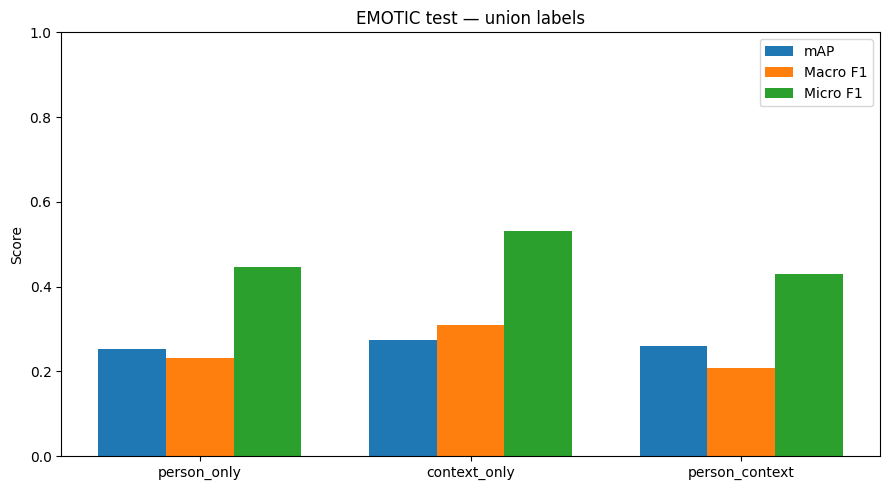

Đánh giá hoàn tất: /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/outputs/resnet_evaluation/20261101-034030


In [16]:
import matplotlib.pyplot as plt

comparison_rows = []
for name in EXPERIMENTS:
    metrics = standard_results["union"][name]
    comparison_rows.append({
        "model": name,
        "map": metrics["map"],
        "macro_f1": metrics["macro_f1"],
        "micro_f1": metrics["micro_f1"],
        "macro_precision": metrics["macro_precision"],
        "macro_recall": metrics["macro_recall"],
    })

with (METRIC_DIR / "model_comparison.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(comparison_rows[0]))
    writer.writeheader()
    writer.writerows(comparison_rows)

labels = [row["model"] for row in comparison_rows]
x = np.arange(len(labels))
width = 0.25
fig, axis = plt.subplots(figsize=(9, 5))
axis.bar(x - width, [row["map"] for row in comparison_rows], width, label="mAP")
axis.bar(x, [row["macro_f1"] for row in comparison_rows], width, label="Macro F1")
axis.bar(x + width, [row["micro_f1"] for row in comparison_rows], width, label="Micro F1")
axis.set_xticks(x, labels)
axis.set_ylim(0, 1)
axis.set_ylabel("Score")
axis.set_title("EMOTIC test — union labels")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", dpi=160)
plt.show()

summary = {
    "run_id": RUN_ID,
    "git_commit": commit,
    "selected_models": selected_exports,
    "standard_union": {
        name: {key: value for key, value in standard_results["union"][name].items() if key != "per_class"}
        for name in EXPERIMENTS
    },
    "bootstrap": bootstrap_results,
    "region_ablation": ablation_results,
    "target_swap": swap_results,
    "artifacts": {
        "predictions": str(PREDICTION_DIR),
        "metrics": str(METRIC_DIR),
        "figures": str(FIGURE_DIR),
    },
}
(RUN_DIR / "run_summary.json").write_text(
    json.dumps(json_safe(summary), ensure_ascii=False, indent=2), encoding="utf-8"
)

required = [
    RUN_DIR / "config.json", RUN_DIR / "environment.txt",
    RUN_DIR / "selected_models.json", RUN_DIR / "run_summary.json",
    METRIC_DIR / "standard_evaluation.json",
    METRIC_DIR / "thresholds.json",
    METRIC_DIR / "paired_bootstrap.json",
    METRIC_DIR / "region_ablation.json",
    METRIC_DIR / "target_swap.json",
    METRIC_DIR / "model_comparison.csv",
    FIGURE_DIR / "model_comparison.png",
]
missing = [str(path) for path in required if not path.is_file()]
assert not missing, f"Thiếu artifact: {missing}"
print("Đánh giá hoàn tất:", RUN_DIR)
